**Segmentasi Citra Berbasis Similaritas**

---

### 1. Konsep Segmentasi Berbasis Similaritas

Segmentasi berbasis similaritas mengelompokkan piksel-piksel yang memiliki kesamaan nilai intensitas, tekstur, atau atribut lainnya. Pendekatan ini berfokus pada keseragaman lokal atau global dalam citra untuk memisahkan objek dari latar belakang.

Metode populer:

* *Global Thresholding*
* *Otsu’s Method*
* *Optimal Thresholding Iteratif*
* *Adaptive Thresholding*
* *Histogram of Gradient (HoG)*

---

### 2. Global Thresholding

#### Konsep:

Global thresholding membagi piksel menjadi dua kelompok (foreground/objek dan background/latar belakang) berdasarkan nilai ambang (threshold) tetap.

#### Implementasi:

```python
import cv2
import matplotlib.pyplot as plt

img = cv2.imread('image.jpg', 0)
_, thresh = cv2.threshold(img, 127, 255, cv2.THRESH_BINARY)

plt.imshow(thresh, cmap='gray')
plt.title('Global Thresholding')
plt.axis('off')
plt.show()
```

#### Eksperimen:

```python
for t in [50, 100, 150, 200]:
    _, th = cv2.threshold(img, t, 255, cv2.THRESH_BINARY)
    plt.figure(), plt.imshow(th, cmap='gray')
    plt.title(f'Threshold: {t}'), plt.axis('off')
```

---

### 3. Otsu’s Method

#### Konsep:

Otsu mencari ambang optimal dengan meminimalkan variansi intra-kelas.

#### Implementasi:

```python
_, otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
plt.imshow(otsu, cmap='gray')
plt.title('Otsu Thresholding')
plt.axis('off')
plt.show()
```

#### Visualisasi Histogram:

```python
plt.hist(img.ravel(), bins=256, range=[0,256])
plt.axvline(_, color='r', label=f'Threshold: {_:.2f}')
plt.title('Histogram dan Threshold Otsu')
plt.legend()
plt.show()
```

---

### 4. Optimal Thresholding (Iteratif)

#### Konsep:

1. Tentukan threshold awal (misal rata-rata intensitas)
2. Kelompokkan piksel menjadi dua berdasarkan threshold
3. Hitung rata-rata masing-masing kelompok
4. Update threshold sebagai rata-rata dari dua nilai rata-rata tersebut
5. Ulangi hingga konvergen

#### Implementasi:

```python
def optimal_threshold(img):
    T = img.mean()
    while True:
        G1 = img[img > T]
        G2 = img[img <= T]
        new_T = (G1.mean() + G2.mean()) / 2
        if abs(T - new_T) < 1:
            break
        T = new_T
    return T

T = optimal_threshold(img)
ret, opt_thresh = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)
plt.imshow(opt_thresh, cmap='gray')
plt.title(f'Optimal Threshold = {T:.2f}')
plt.axis('off')
plt.show()
```

---

### 5. Adaptive Thresholding

#### Konsep:

* Menentukan threshold untuk tiap piksel berdasarkan lingkungan lokal (blok kecil).
* Menggunakan ambang lokal berdasarkan rata-rata atau Gaussian dari lingkungan sekitar setiap piksel.

#### Implementasi:

```python
adaptive = cv2.adaptiveThreshold(img, 255,
                                 cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
plt.imshow(adaptive, cmap='gray')
plt.title('Adaptive Thresholding')
plt.axis('off')
plt.show()
```

#### Eksperimen Blok Ukuran:

```python
for block_size in [11, 15, 25]:
    adaptive = cv2.adaptiveThreshold(img, 255,
                                     cv2.ADAPTIVE_THRESH_MEAN_C,
                                     cv2.THRESH_BINARY, block_size, 2)
    plt.figure(), plt.imshow(adaptive, cmap='gray')
    plt.title(f'Block size: {block_size}')
```

---

### 6. Histogram of Oriented Gradient (HoG)

#### Konsep:

* Ekstraksi fitur tepi dan orientasi gradien pada blok-blok kecil citra (lokal).
* Digunakan untuk deteksi objek dan segmentasi berbasis fitur.

#### Implementasi (Visualisasi HoG):

```python
from skimage.feature import hog
from skimage import exposure

# Hitung HOG
fd, hog_image = hog(img, orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), visualize=True)

plt.imshow(hog_image, cmap='gray')
plt.title('Histogram of Gradient - Feature Image')
plt.axis('off')
plt.show()
```

#### Eksperimen:

```python
# Hitung HOG
fd, hog_image = hog(img, orientations=8, pixels_per_cell=(16, 16),
                    cells_per_block=(1, 1), visualize=True)

# Rescale HOG untuk visualisasi
hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

plt.figure(figsize=(10, 5))
plt.subplot(121), plt.imshow(img, cmap='gray'), plt.title('Original')
plt.subplot(122), plt.imshow(hog_image_rescaled, cmap='gray'), plt.title('HOG')
plt.show()
```

---

### 7. Integrasi dengan Penyambungan Tepi

Thresholding dapat dikombinasikan dengan penyambungan tepi untuk menyaring hasil tepi:

```python
edges = cv2.Canny(img, 100, 200)
masked = cv2.bitwise_and(edges, edges, mask=thresh)
plt.imshow(masked, cmap='gray')
plt.title('Tepi setelah Thresholding')
plt.axis('off')
plt.show()
```

---

### 8. Kesimpulan

* Segmentasi berbasis similaritas efektif untuk memisahkan objek dengan intensitas homogen.
* Global thresholding cepat namun tidak fleksibel, cocok untuk citra dengan kontras tinggi.
* Metode Otsu, optimal thresholding, dan adaptive thresholding memberikan hasil otomatis, sehingga lebih fleksibel untuk kondisi pencahayaan tidak merata.
* HoG membuka jalan menuju segmentasi berbasis pembelajaran fitur (feature-based segmentation).
* Eksperimen parameter seperti ambang batas dan ukuran blok menunjukkan sensitivitas metode terhadap variasi input.
* Integrasi dengan metode seperti deteksi tepi dapat meningkatkan kualitas segmentasi akhir.

# Implementasi Di Kelas

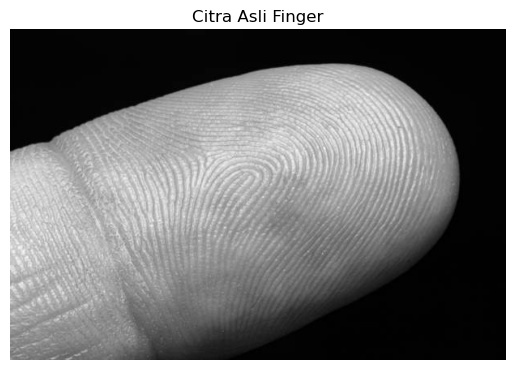

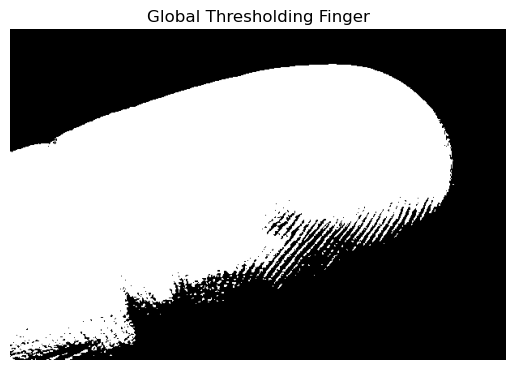

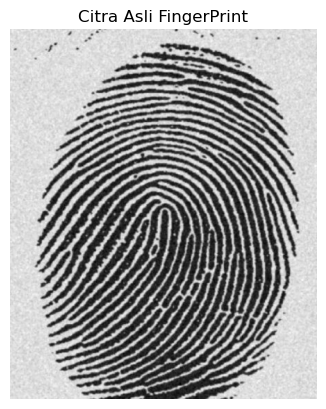

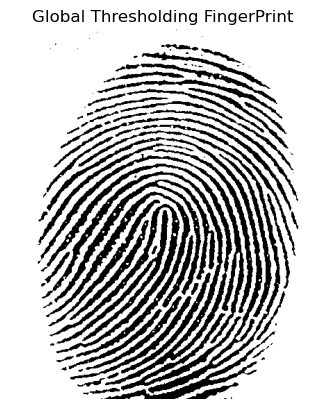

In [14]:
import cv2
import matplotlib.pyplot as plt

img1 = cv2.imread('finger.jpeg', 0)
_, thresh1 = cv2.threshold(img1, 127, 255, cv2.THRESH_BINARY)
img2 = cv2.imread('fingerprint.jpeg', 0)
_, thresh2 = cv2.threshold(img2, 127, 255, cv2.THRESH_BINARY)

plt.imshow(img1, cmap='gray')
plt.title('Citra Asli Finger')
plt.axis('off')
plt.show()

plt.imshow(thresh1, cmap='gray')
plt.title('Global Thresholding Finger')
plt.axis('off')
plt.show()

plt.imshow(img2, cmap='gray')
plt.title('Citra Asli FingerPrint')
plt.axis('off')
plt.show()



plt.imshow(thresh2, cmap='gray')
plt.title('Global Thresholding FingerPrint')
plt.axis('off')
plt.show()

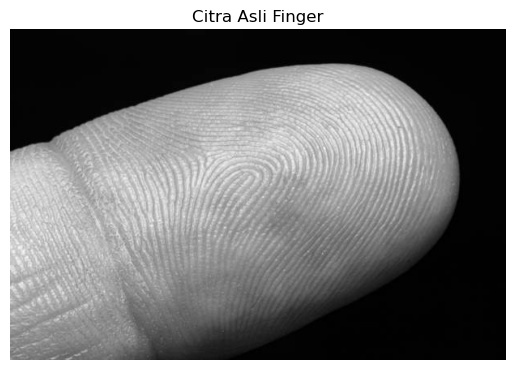

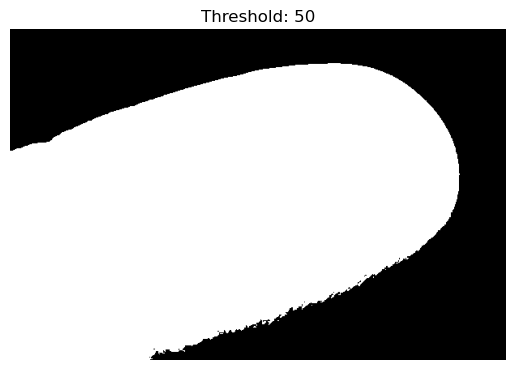

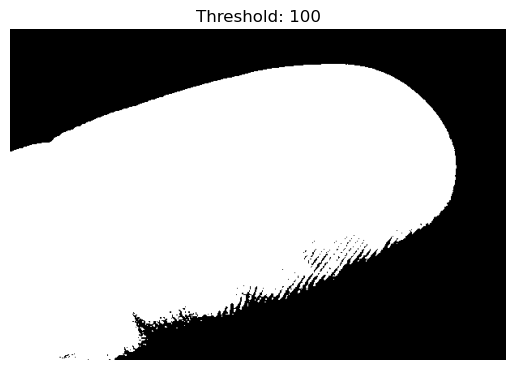

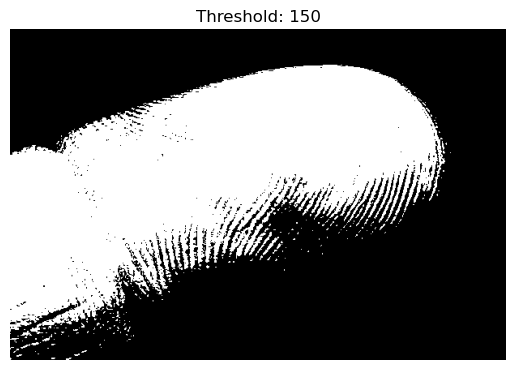

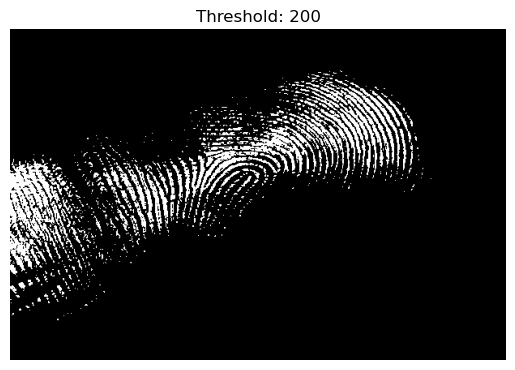

In [11]:
plt.imshow(img1, cmap='gray')
plt.title('Citra Asli Finger')
plt.axis('off')
plt.show()

for t in [50, 100, 150, 200]:
    _, otsu = cv2.threshold(img1, t, 255, cv2.THRESH_BINARY)
    plt.figure()
    plt.imshow(otsu, cmap='gray')
    plt.title(f'Threshold: {t}')
    plt.axis('off')

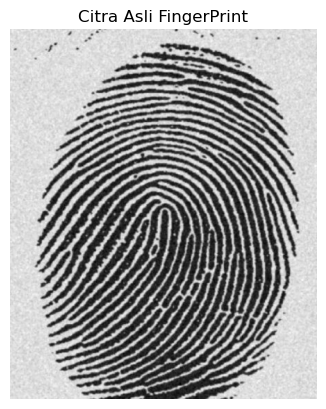

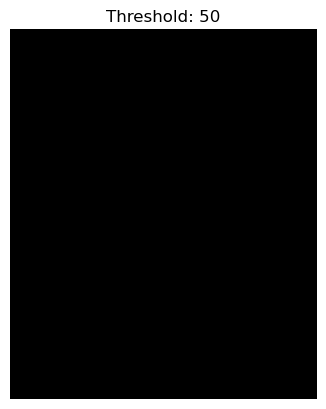

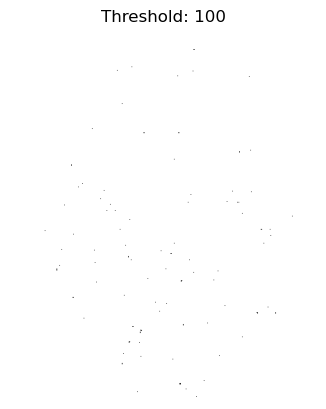

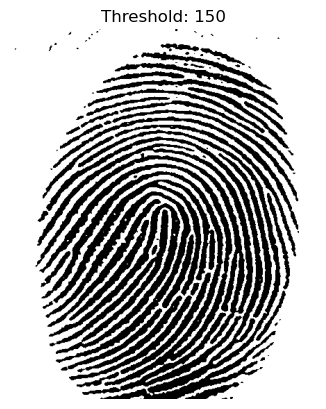

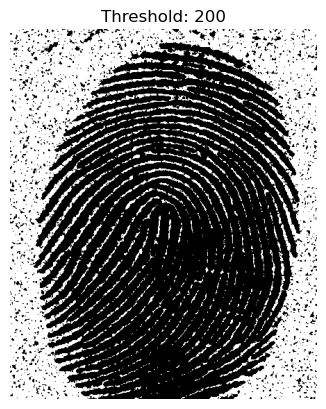

In [13]:
plt.imshow(img2, cmap='gray')
plt.title('Citra Asli FingerPrint')
plt.axis('off')
plt.show()

for t in [50, 100, 150, 200]:
    _, otsu = cv2.threshold(img2, t, 255, cv2.THRESH_BINARY)
    plt.figure()
    plt.imshow(otsu, cmap='gray')
    plt.title(f'Threshold: {t}')
    plt.axis('off')

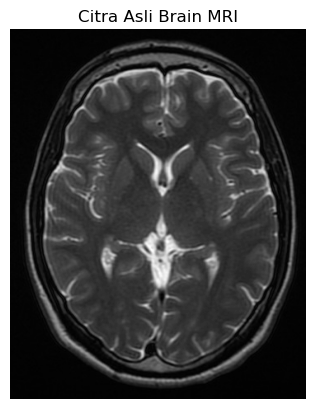

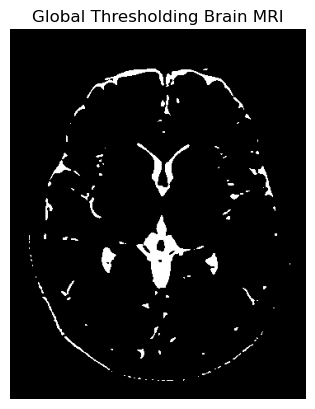

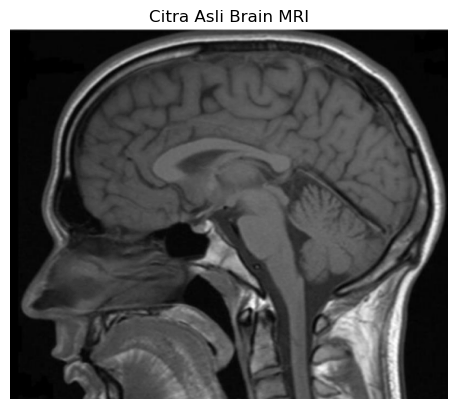

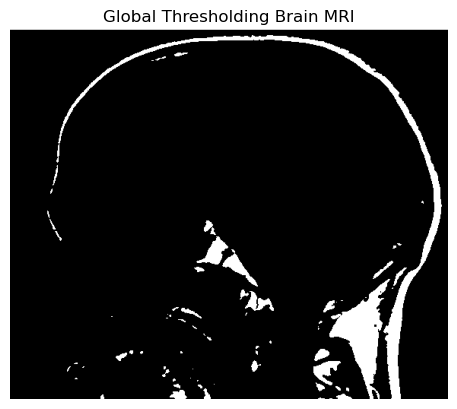

In [ ]:
img3 = cv2.imread('brain_mri_.jpeg', 0)
_, thresh3 = cv2.threshold(img3, 127, 255, cv2.THRESH_BINARY)
img4 = cv2.imread('brain_mri.jpeg', 0)
_, thresh4 = cv2.threshold(img4, 127, 255, cv2.THRESH_BINARY)

plt.imshow(img3, cmap='gray')
plt.title('Citra Asli Brain MRI')
plt.axis('off')
plt.show()

plt.imshow(thresh3, cmap='gray')
plt.title('Global Thresholding Brain MRI')
plt.axis('off')
plt.show()

plt.imshow(img4, cmap='gray')
plt.title('Citra Asli Brain MRI')
plt.axis('off')
plt.show()

plt.imshow(thresh4, cmap='gray')
plt.title('Global Thresholding Brain MRI')
plt.axis('off')
plt.show()

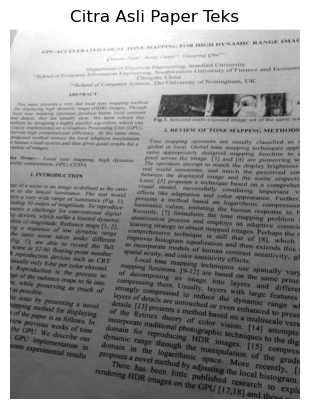

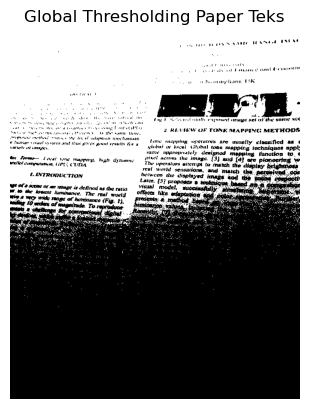

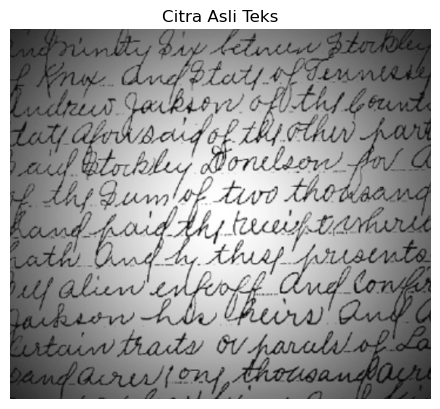

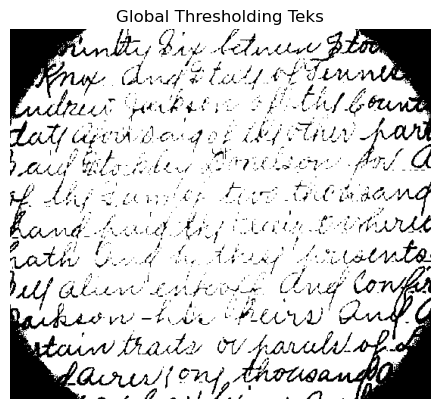

In [16]:
img5 = cv2.imread('paper_teks.jpeg', 0)
_, thresh5 = cv2.threshold(img5, 127, 255, cv2.THRESH_BINARY)
img6 = cv2.imread('teks.jpeg', 0)
_, thresh6 = cv2.threshold(img6, 127, 255, cv2.THRESH_BINARY)

plt.imshow(img5, cmap='gray')
plt.title('Citra Asli Paper Teks')
plt.axis('off')
plt.show()

plt.imshow(thresh5, cmap='gray')
plt.title('Global Thresholding Paper Teks')
plt.axis('off')
plt.show()

plt.imshow(img6, cmap='gray')
plt.title('Citra Asli Teks')
plt.axis('off')
plt.show()

plt.imshow(thresh6, cmap='gray')
plt.title('Global Thresholding Teks')
plt.axis('off')
plt.show()

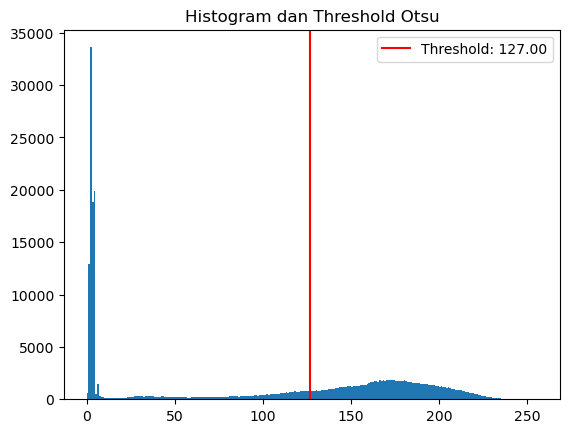

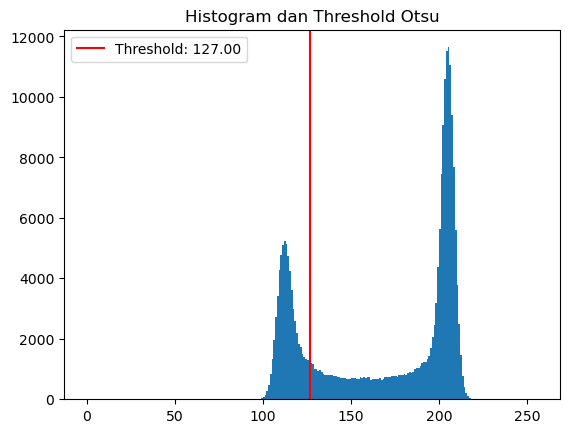

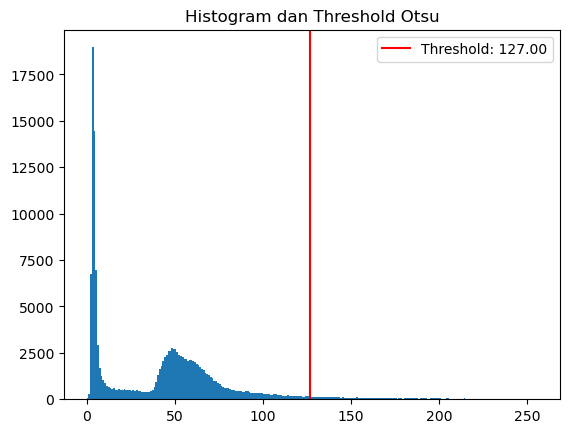

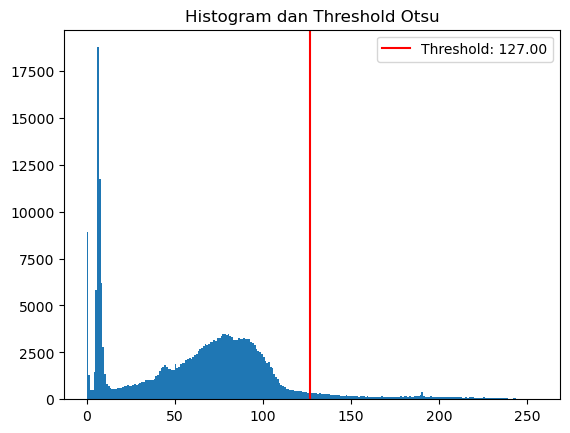

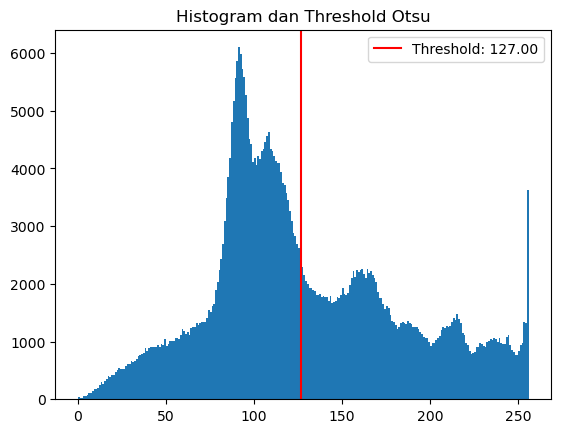

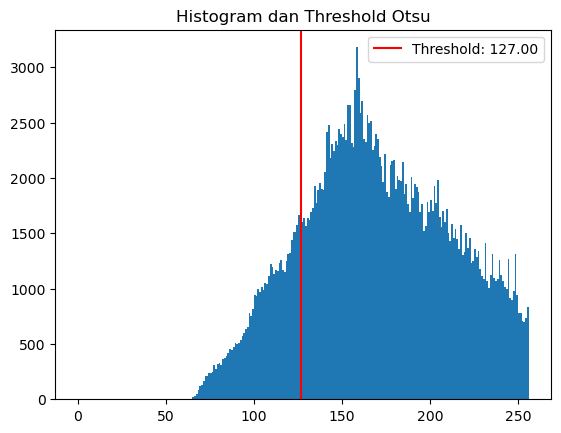

In [18]:
for i in [img1, img2, img3, img4, img5, img6]:
    plt.hist(i.ravel(), bins=256, range=[0,256])
    plt.axvline(_, color='r', label=f'Threshold: {_:.2f}')
    plt.title('Histogram dan Threshold Otsu')
    plt.legend()
    plt.show()

In [ ]:
def optimal_threshold(img):
    T = img.mean()
    while True:
        G1 = img[img > T]
        G2 = img[img <= T]
        new_T = (G1.mean() + G2.mean()) / 2
        if abs(T - new_T) < 1:
            break
        T = new_T
    return T

T = optimal_threshold(img)
ret, opt_thresh = cv2.threshold(img, T, 255, cv2.THRESH_BINARY)
plt.imshow(opt_thresh, cmap='gray')
plt.title(f'Optimal Threshold = {T:.2f}')
plt.axis('off')
plt.show()

In [ ]:
adaptive = cv2.adaptiveThreshold(img, 255,
                                 cv2.ADAPTIVE_THRESH_MEAN_C,
                                 cv2.THRESH_BINARY, 11, 2)
plt.imshow(adaptive, cmap='gray')
plt.title('Adaptive Thresholding')
plt.axis('off')
plt.show()

In [ ]:
for block_size in [11, 15, 25]:
    adaptive = cv2.adaptiveThreshold(img, 255,
                                     cv2.ADAPTIVE_THRESH_MEAN_C,
                                     cv2.THRESH_BINARY, block_size, 2)
    plt.figure(), plt.imshow(adaptive, cmap='gray')
    plt.title(f'Block size: {block_size}')

In [ ]:
from skimage.feature import hog
from skimage import exposure

# Hitung HOG
fd, hog_image = hog(img, orientations=9, pixels_per_cell=(8, 8),
                    cells_per_block=(2, 2), visualize=True)

plt.imshow(hog_image, cmap='gray')
plt.title('Histogram of Gradient - Feature Image')
plt.axis('off')
plt.show()

In [17]:
for i in [img1, img2, img3, img4, img5, img6]:
    fd, hog_image = hog(i, orientations=8, pixels_per_cell=(16, 16),
                        cells_per_block=(1, 1), visualize=True)

    # Rescale HOG untuk visualisasi
    hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))

    plt.figure(figsize=(10, 5))
    plt.subplot(121), plt.imshow(i, cmap='gray'), plt.title('Original')
    plt.subplot(122), plt.imshow(hog_image_rescaled, cmap='gray'), plt.title('HOG')
    plt.show()

NameError: name 'hog' is not defined

In [ ]:
edges = cv2.Canny(img, 100, 200)
masked = cv2.bitwise_and(edges, edges, mask=thresh)
plt.imshow(masked, cmap='gray')
plt.title('Tepi setelah Thresholding')
plt.axis('off')
plt.show()